# Notebook 15: Q-Learning state coverage and duration

This notebook tests whether broader pollution experience, longer training, or a different EDI discretization improves learned policies. Reward equations and environmental settings stay fixed.

## Experiment design

- Train separate policies under low, reference, and high pollutant settings. Evaluate each policy under all three settings.
- Compare checkpoints at 300, 1,000, and 3,000 episodes using seeds 11, 23, and 37.
- Keep the local, global, and mixed rewards and all Q-Learning settings from Notebook 14.
- Compare coarse, current, and finer EDI bins at 1,000 episodes, using reference conditions for training and all three conditions for evaluation.
- Report evaluation outcomes, unique training states, unseen evaluation states, and action distributions. Baselines use the same evaluation settings.

Pollution settings alter the pollutant parameter scenarios only. Income retention stays at 60%, development costs stay constant, and episodes remain 40 years.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

from study_3_pollutant_dynamics.rl_formulation import ACTION_NAMES, STATE_BIN_EDGES
from study_3_pollutant_dynamics.rl_experiments import run_training_coverage_diagnostics

In [2]:
def number_of_states(bin_edges):
    state_count = 1
    for boundaries in bin_edges.values():
        state_count *= len(boundaries) + 1
    return state_count

In [3]:
TRAINING_SCENARIOS = ["low", "reference", "high"]
EVALUATION_SCENARIOS = ["low", "reference", "high"]
REWARD_MODES = ["local", "global", "mixed"]
TRAINING_SEEDS = [11, 23, 37]
EPISODE_CHECKPOINTS = [300, 1000, 3000]
EPISODE_YEARS = 40
INCOME_RETENTION = 0.6
STARTING_CURRENCY_MULTIPLIER = 1.0
DEVELOPMENT_COST_SHAPE = "constant"
RESULTS_DIRECTORY = "study_3_pollutant_dynamics/results/rl_coverage"

COARSE_EDI_EDGES = (60, 80, 95)
FINE_EDI_EDGES = (60, 65, 70, 75, 80, 85, 90, 93, 95, 97, 98, 99)
COARSE_EDGES = dict(STATE_BIN_EDGES)
COARSE_EDGES["EDI"] = COARSE_EDI_EDGES
FINE_EDGES = dict(STATE_BIN_EDGES)
FINE_EDGES["EDI"] = FINE_EDI_EDGES
ENCODINGS = {"coarse": COARSE_EDGES, "current": STATE_BIN_EDGES, "fine": FINE_EDGES}

encoding_summary = pd.DataFrame([{"encoding": name, "EDI_bins": len(edges["EDI"]) + 1,
                                  "possible_states_per_agent": number_of_states(edges),
                                  "actions_per_agent": len(ACTION_NAMES)}
                                 for name, edges in ENCODINGS.items()])
display(encoding_summary)

,encoding,EDI_bins,possible_states_per_agent,actions_per_agent
0,coarse,4,31104,8
1,current,7,54432,8
2,fine,13,101088,8


## Train across pollution scenarios

The training helper saves Q-tables at each checkpoint and records episode returns and state visits. Evaluation uses a no-action reference path matched to the evaluation scenario. This keeps each policy's pollution reward on the same scenario-specific baseline.

In [4]:
duration_outputs = run_training_coverage_diagnostics(
    RESULTS_DIRECTORY, TRAINING_SCENARIOS, EVALUATION_SCENARIOS, REWARD_MODES, TRAINING_SEEDS,
    EPISODE_CHECKPOINTS, STATE_BIN_EDGES, episode_years=EPISODE_YEARS,
    income_retention_fraction=INCOME_RETENTION,
    starting_currency_multiplier=STARTING_CURRENCY_MULTIPLIER,
    development_cost_shape=DEVELOPMENT_COST_SHAPE,
)
duration_training = pd.DataFrame(duration_outputs[0])
duration_evaluation = pd.DataFrame(duration_outputs[1])
duration_trajectories = pd.DataFrame(duration_outputs[2])
duration_actions = pd.DataFrame(duration_outputs[3])
duration_fixed = pd.DataFrame(duration_outputs[4])

duration_training.to_csv(RESULTS_DIRECTORY + "/training_history.csv", index=False)
duration_evaluation.to_csv(RESULTS_DIRECTORY + "/evaluation_results.csv", index=False)
duration_trajectories.to_csv(RESULTS_DIRECTORY + "/evaluation_trajectories.csv", index=False)
duration_actions.to_csv(RESULTS_DIRECTORY + "/action_frequencies.csv", index=False)
duration_fixed.to_csv(RESULTS_DIRECTORY + "/fixed_baselines.csv", index=False)

In [5]:
settings = {"training_scenarios": TRAINING_SCENARIOS, "evaluation_scenarios": EVALUATION_SCENARIOS,
            "reward_modes": REWARD_MODES, "training_seeds": TRAINING_SEEDS,
            "episode_checkpoints": EPISODE_CHECKPOINTS, "episode_years": EPISODE_YEARS,
            "income_retention_fraction": INCOME_RETENTION,
            "starting_currency_multiplier": STARTING_CURRENCY_MULTIPLIER,
            "development_cost_shape": DEVELOPMENT_COST_SHAPE, "encoding": STATE_BIN_EDGES,
            "epsilon_start": 1.0, "epsilon_decay": 0.99, "epsilon_minimum": 0.05,
            "learning_rate": 0.2, "discount_factor": 0.95}

with open(RESULTS_DIRECTORY + "/settings.json", "w", encoding="utf-8") as output_file:
    json.dump(settings, output_file, indent=2)

print("Training rows:", len(duration_training), "evaluation runs:", len(duration_evaluation))
print("Fixed baseline runs:", len(duration_fixed), "saved Q-table files:", len(EPISODE_CHECKPOINTS) * len(TRAINING_SCENARIOS) * len(REWARD_MODES) * len(TRAINING_SEEDS) * 4)

Training rows: 81000 evaluation runs: 243
Fixed baseline runs: 15 saved Q-table files: 324


## State coverage and training returns

The first table shows how many distinct encoded states and state-action pairs were visited by each checkpoint. The chart shows training returns; use evaluation results below to judge policy progress.

In [6]:
training_coverage = duration_training[duration_training["episode"].isin(EPISODE_CHECKPOINTS)].groupby(
    ["training_scenario", "reward_mode", "episode"], sort=False
).agg(mean_unique_states=("visited_states_across_regions", "mean"),
     mean_visited_state_actions=("visited_state_action_pairs", "mean"),
     mean_epsilon=("epsilon", "mean")).reset_index()
display(training_coverage.round(3))

,training_scenario,reward_mode,episode,mean_unique_states,mean_visited_state_actions,mean_epsilon
0,low,local,300,129.000,818.333,0.05
1,low,local,1000,132.667,849.333,0.05
2,low,local,3000,134.667,876.000,0.05
3,low,global,300,124.000,785.000,0.05
4,low,global,1000,126.333,805.667,0.05
5,low,global,3000,129.000,826.333,0.05
6,low,mixed,300,129.000,823.333,0.05
7,low,mixed,1000,131.333,846.667,0.05
8,low,mixed,3000,134.000,881.667,0.05
9,reference,local,300,199.000,1163.000,0.05


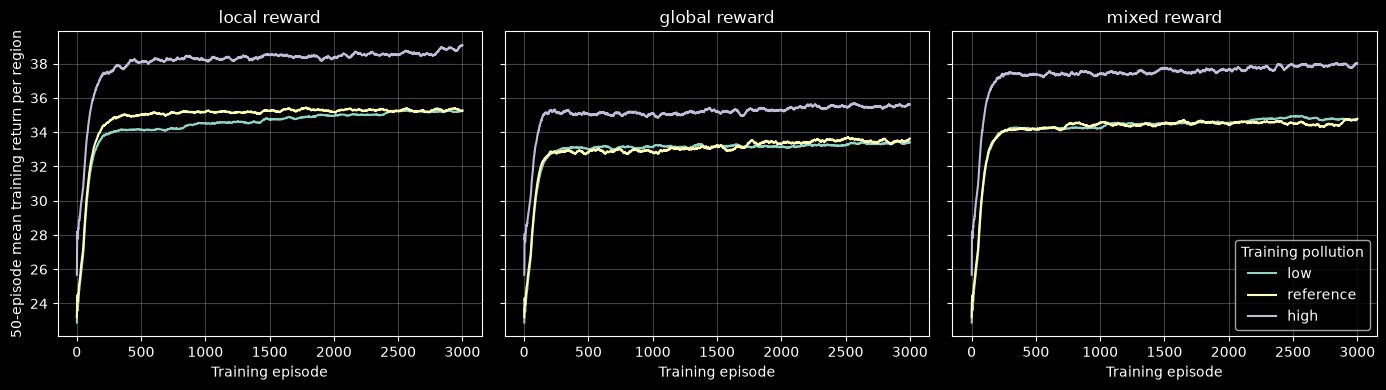

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for axis, reward_mode in zip(axes, REWARD_MODES):
    selected = duration_training[duration_training["reward_mode"] == reward_mode]
    for scenario in TRAINING_SCENARIOS:
        group = selected[selected["training_scenario"] == scenario]
        trend = group.groupby("episode")["mean_cumulative_reward_per_region"].mean().rolling(50, min_periods=1).mean()
        axis.plot(trend.index, trend.values, label=scenario)
    axis.set_title(reward_mode + " reward")
    axis.set_xlabel("Training episode")
    axis.grid(alpha=0.25)
axes[0].set_ylabel("50-episode mean training return per region")
axes[-1].legend(title="Training pollution")
plt.tight_layout()
plt.show()

## Evaluation progress

The next table averages the three training seeds. Each row compares a training condition, reward structure, and episode checkpoint on the same pollution condition used for training. The plots track EDI, cumulative net income, and pollution under matched conditions.

In [8]:
matched_evaluation = duration_evaluation[duration_evaluation["training_scenario"] == duration_evaluation["evaluation_scenario"]]

matched_summary = matched_evaluation.groupby(
    ["training_scenario", "reward_mode", "training_episodes"], sort=False
).agg(training_seeds=("training_seed", "nunique"), mean_final_EDI=("final_mean_EDI", "mean"),
     mean_average_EDI=("average_EDI", "mean"), mean_cumulative_net_income=("cumulative_net_income", "mean"),
     mean_currency=("final_mean_currency", "mean"), mean_development_spending=("development_spending", "mean"),
     mean_mitigation_spending=("mitigation_spending", "mean"), mean_CO2_ppm=("final_CO2_ppm", "mean"),
     mean_PM2_5=("final_mean_PM2.5_ug_m3", "mean"), mean_nitrate=("final_mean_nitrate_mg_N_L", "mean"),
     mean_lead_total=("final_mean_lead_total_kg", "mean"), mean_unseen_state_fraction=("unseen_state_visit_fraction", "mean")
).reset_index()
display(matched_summary.round(3))

,training_scenario,reward_mode,training_episodes,training_seeds,mean_final_EDI,mean_average_EDI,mean_cumulative_net_income,mean_currency,mean_development_spending,mean_mitigation_spending,mean_CO2_ppm,mean_PM2_5,mean_nitrate,mean_lead_total,mean_unseen_state_fraction
0,low,local,300,3,97.167,83.688,18540.695,1810.271,3216.667,3166.667,505.479,8.567,2.116,8.106,0.0
1,low,local,1000,3,97.417,83.762,18543.756,1751.147,3241.667,3380.000,505.466,8.567,2.093,8.025,0.0
2,low,local,3000,3,98.083,84.048,18532.739,1694.494,3308.333,3533.333,505.615,8.567,2.111,7.927,0.0
3,low,global,300,3,95.250,81.898,18564.187,1805.045,3025.000,3393.333,504.892,8.565,2.008,7.910,0.0
4,low,global,1000,3,95.333,81.900,18564.187,1786.295,3033.333,3460.000,504.892,8.565,2.008,7.910,0.0
5,low,global,3000,3,95.500,81.906,18558.381,1779.590,3050.000,3466.667,504.990,8.565,2.011,7.900,0.0
6,low,mixed,300,3,96.833,83.485,18550.461,1750.069,3183.333,3446.667,505.322,8.566,2.058,7.994,0.0
7,low,mixed,1000,3,96.833,83.485,18550.461,1740.069,3183.333,3486.667,505.321,8.566,2.049,7.979,0.0
8,low,mixed,3000,3,97.583,83.915,18532.232,1735.251,3258.333,3420.000,505.702,8.565,2.011,7.893,0.0
9,reference,local,300,3,97.250,83.673,17478.142,1600.471,3225.000,3360.000,527.718,8.578,2.573,14.320,0.0


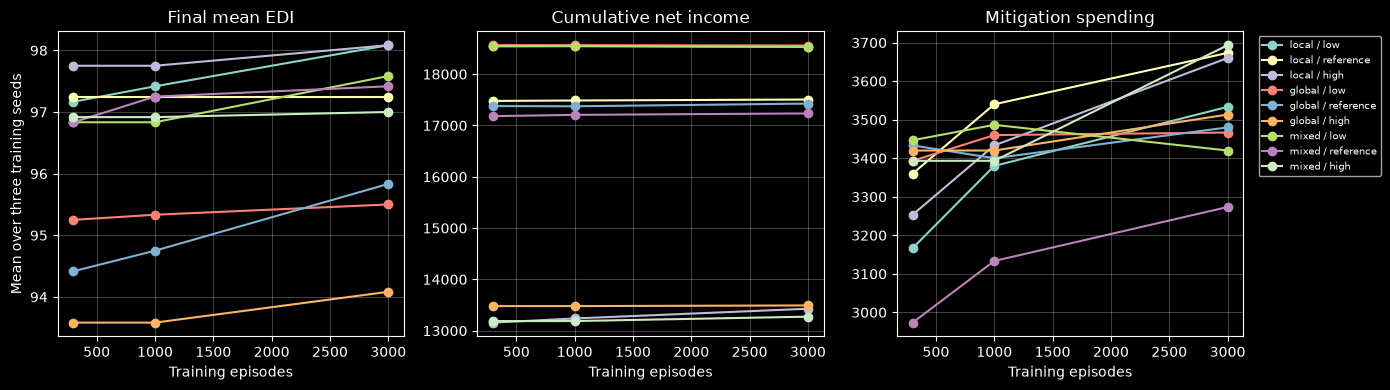

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, (metric, title) in zip(axes, [("final_mean_EDI", "Final mean EDI"),
                                        ("cumulative_net_income", "Cumulative net income"),
                                        ("mitigation_spending", "Mitigation spending")]):
    chart = matched_evaluation.groupby(["training_scenario", "reward_mode", "training_episodes"], sort=False)[metric].mean().reset_index()
    for reward_mode in REWARD_MODES:
        for scenario in TRAINING_SCENARIOS:
            selected = chart[(chart["reward_mode"] == reward_mode) & (chart["training_scenario"] == scenario)]
            axis.plot(selected["training_episodes"], selected[metric], marker="o",
                      label=reward_mode + " / " + scenario)
    axis.set_title(title)
    axis.set_xlabel("Training episodes")
    axis.grid(alpha=0.25)
axes[0].set_ylabel("Mean over three training seeds")
axes[-1].legend(fontsize=7, bbox_to_anchor=(1.03, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Generalization and unseen-state rates

A policy trained on one pollution scenario is also evaluated on the other two. `unseen_state_visit_fraction` is the share of acted-on region-year observations whose encoded state was not in that policy's training Q-table.

In [10]:
coverage_evaluation = duration_evaluation.groupby(
    ["training_scenario", "evaluation_scenario", "reward_mode", "training_episodes"], sort=False
).agg(training_seeds=("training_seed", "nunique"), mean_unique_training_states=("unique_training_states", "mean"),
     mean_unseen_visits=("unseen_state_visits", "mean"), mean_unseen_state_fraction=("unseen_state_visit_fraction", "mean"),
     mean_unique_unseen_states=("unique_unseen_states", "mean"), mean_final_EDI=("final_mean_EDI", "mean"),
     mean_net_income=("cumulative_net_income", "mean"), mean_mitigation_spending=("mitigation_spending", "mean")
).reset_index()
display(coverage_evaluation.round(3))

,training_scenario,evaluation_scenario,reward_mode,training_episodes,training_seeds,mean_unique_training_states,mean_unseen_visits,mean_unseen_state_fraction,mean_unique_unseen_states,mean_final_EDI,mean_net_income,mean_mitigation_spending
0,low,low,local,300,3,129.000,0.0,0.000,0.0,97.167,18540.695,3166.667
1,low,reference,local,300,3,129.000,98.0,0.612,21.0,79.917,16999.740,1120.000
2,low,high,local,300,3,129.000,160.0,1.000,33.0,65.000,10988.593,0.000
3,low,low,local,1000,3,132.667,0.0,0.000,0.0,97.417,18543.756,3380.000
4,low,reference,local,1000,3,132.667,98.0,0.612,21.0,79.917,16999.740,1120.000
...,...,...,...,...,...,...,...,...,...,...,...,...
76,high,reference,mixed,1000,3,168.000,160.0,1.000,32.0,65.000,15582.365,0.000
77,high,high,mixed,1000,3,168.000,0.0,0.000,0.0,96.917,13187.894,3393.333
78,high,low,mixed,3000,3,171.333,160.0,1.000,33.0,65.000,16797.517,0.000
79,high,reference,mixed,3000,3,171.333,160.0,1.000,32.0,65.000,15582.365,0.000


In [11]:
coverage_matrix = duration_evaluation[duration_evaluation["training_episodes"] == max(EPISODE_CHECKPOINTS)].groupby(
    ["training_scenario", "evaluation_scenario"], sort=False
)["unseen_state_visit_fraction"].mean().unstack()
display(coverage_matrix.round(3))

evaluation_scenario,low,reference,high
training_scenario,,,
low,0.000,0.543,1.0
reference,0.295,0.000,1.0
high,1.000,1.000,0.0


## Comparison with fixed policies

Fixed baselines use the same scenario-specific environment and economic settings as evaluation. The summary reports both economic and environmental outcomes so a policy is not selected by EDI alone.

In [12]:
learned_final = duration_evaluation[(duration_evaluation["training_episodes"] == max(EPISODE_CHECKPOINTS)) &
                                    (duration_evaluation["training_scenario"] == duration_evaluation["evaluation_scenario"])].copy()

learned_final["policy_type"] = "learned"
learned_final["policy"] = learned_final["reward_mode"] + " Q-learning"
fixed_comparison = duration_fixed.copy()

fixed_comparison["reward_mode"] = "fixed"
fixed_comparison["training_scenario"] = fixed_comparison["evaluation_scenario"]
comparison_rows = pd.concat([learned_final, fixed_comparison], ignore_index=True, sort=False)

comparison_summary = comparison_rows.groupby(["evaluation_scenario", "policy_type", "policy"], sort=False).agg(
    training_seeds=("training_seed", "nunique"), mean_final_EDI=("final_mean_EDI", "mean"),
     minimum_region_EDI=("final_min_EDI", "min"), average_EDI=("average_EDI", "mean"),
     cumulative_net_income=("cumulative_net_income", "mean"), final_currency=("final_mean_currency", "mean"),
     development_spending=("development_spending", "mean"), mitigation_spending=("mitigation_spending", "mean"),
     final_CO2_ppm=("final_CO2_ppm", "mean"), final_PM2_5=("final_mean_PM2.5_ug_m3", "mean"),
     final_nitrate=("final_mean_nitrate_mg_N_L", "mean"), final_lead_total=("final_mean_lead_total_kg", "mean")
).reset_index()
display(comparison_summary.round(3))

,evaluation_scenario,policy_type,policy,training_seeds,mean_final_EDI,minimum_region_EDI,average_EDI,cumulative_net_income,final_currency,development_spending,mitigation_spending,final_CO2_ppm,final_PM2_5,final_nitrate,final_lead_total
0,low,learned,local Q-learning,3,98.083,93.0,84.048,18532.739,1694.494,3308.333,3533.333,505.615,8.567,2.111,7.927
1,low,learned,global Q-learning,3,95.500,90.0,81.906,18558.381,1779.590,3050.000,3466.667,504.990,8.565,2.011,7.900
2,low,learned,mixed Q-learning,3,97.583,90.0,83.915,18532.232,1735.251,3258.333,3420.000,505.702,8.565,2.011,7.893
3,reference,learned,local Q-learning,3,97.250,90.0,83.740,17505.851,1526.294,3225.000,3673.333,527.635,8.572,2.489,14.119
4,reference,learned,global Q-learning,3,95.833,88.0,82.367,17426.352,1598.119,3083.333,3480.000,527.497,8.573,2.533,14.087
5,reference,learned,mixed Q-learning,3,97.417,90.0,83.631,17234.668,1581.450,3241.667,3273.333,527.920,8.577,2.572,14.333
6,high,learned,local Q-learning,3,98.083,93.0,84.062,13428.012,897.118,3308.333,3660.000,578.094,8.613,3.031,55.088
7,high,learned,global Q-learning,3,94.083,81.0,81.592,13492.108,1043.400,2908.333,3513.333,577.688,8.634,3.078,54.271
8,high,learned,mixed Q-learning,3,97.000,90.0,83.585,13273.604,892.707,3200.000,3693.333,578.135,8.625,3.081,55.027
9,low,fixed,no_development_no_investment,0,65.000,55.0,65.000,16797.517,3144.628,0.000,0.000,503.220,8.563,1.806,9.512


## Action choices by learned reward

Compare the actions the policies selected under matched training and evaluation scenarios at the 3,000-episode checkpoint.

In [13]:
matched_actions = duration_actions[(duration_actions["policy_type"] == "learned") &
                                   (duration_actions["training_scenario"] == duration_actions["evaluation_scenario"]) &(duration_actions["training_episodes"] == max(EPISODE_CHECKPOINTS))]

action_summary = matched_actions.groupby(["training_scenario", "reward_mode", "action"], sort=False)["count"].sum().unstack(fill_value=0)
display(action_summary)

action                         maintain  develop  prevention  \
training_scenario reward_mode                                  
low               local               5      120           6   
                  global             43      103          23   
                  mixed              16      132           2   
reference         local               8      106           9   
                  global             43      109          13   
                  mixed              20      130           7   
high              local               7      140           2   
                  global             59      108          20   
                  mixed              17      118           2   

action                         develop_prevention  cleanup  develop_cleanup  \
training_scenario reward_mode                                                 
low               local                       109        0              110   
                  global                       81        1               84   
                  mixed                        92        0              112   
reference         local                       109        0               99   
                  global                       80        4              101   
                  mixed                       108        0              110   
high              local                        94        1               92   
                  global                      102        9               73   
                  mixed                       113        1               96   

action                         balanced  develop_balanced  
training_scenario reward_mode                              
low               local              12               118  
                  global             25               120  
                  mixed              19               107  
reference         local               3               146  
                  global             26               104  
                  mixed              20                85  
high              local               6               138  
                  global             14                95  
                  mixed              19               114

## Test EDI discretization

Only EDI bin edges change in this comparison. The coarse encoding reduces the state count; the fine encoding adds distinctions around development milestones while preserving the other seven features. Training uses reference pollution conditions for 1,000 episodes and the same three seeds and reward modes.

In [14]:
discretization_outputs = {}

for encoding_name in ["coarse", "fine"]:
    result_directory = RESULTS_DIRECTORY + "/discretization_" + encoding_name
    outputs = run_training_coverage_diagnostics(
        result_directory, ["reference"], EVALUATION_SCENARIOS, REWARD_MODES, TRAINING_SEEDS, [1000],
        ENCODINGS[encoding_name], episode_years=EPISODE_YEARS,
        income_retention_fraction=INCOME_RETENTION,
        starting_currency_multiplier=STARTING_CURRENCY_MULTIPLIER,
        development_cost_shape=DEVELOPMENT_COST_SHAPE,
        include_fixed_baselines=False, encoding_name=encoding_name)
    discretization_outputs[encoding_name] = outputs

coarse_eval = pd.DataFrame(discretization_outputs["coarse"][1])
fine_eval = pd.DataFrame(discretization_outputs["fine"][1])
current_eval = duration_evaluation[(duration_evaluation["training_scenario"] == "reference") &
                                   (duration_evaluation["training_episodes"] == 1000)].copy()

In [15]:
current_eval["encoding"] = "current"
discretization_eval = pd.concat([current_eval, coarse_eval, fine_eval], ignore_index=True, sort=False)
discretization_eval.to_csv(RESULTS_DIRECTORY + "/discretization_evaluation.csv", index=False)
discretization_summary = discretization_eval.groupby(["encoding", "reward_mode", "evaluation_scenario"], sort=False).agg(
    training_seeds=("training_seed", "nunique"), mean_unique_training_states=("unique_training_states", "mean"),
     mean_unseen_state_fraction=("unseen_state_visit_fraction", "mean"), mean_final_EDI=("final_mean_EDI", "mean"),
     mean_net_income=("cumulative_net_income", "mean"), mean_currency=("final_mean_currency", "mean"),
     mean_development_spending=("development_spending", "mean"), mean_mitigation_spending=("mitigation_spending", "mean"),
     mean_CO2_ppm=("final_CO2_ppm", "mean"), mean_PM2_5=("final_mean_PM2.5_ug_m3", "mean"),
     mean_nitrate=("final_mean_nitrate_mg_N_L", "mean"), mean_lead_total=("final_mean_lead_total_kg", "mean")
).reset_index()
display(discretization_summary.round(3))

,encoding,reward_mode,evaluation_scenario,training_seeds,mean_unique_training_states,mean_unseen_state_fraction,mean_final_EDI,mean_net_income,mean_currency,mean_development_spending,mean_mitigation_spending,mean_CO2_ppm,mean_PM2_5,mean_nitrate,mean_lead_total
0,current,local,low,3,203.333,0.298,92.083,18458.286,1991.660,2708.333,2900.000,505.586,8.568,2.181,8.007
1,current,local,reference,3,203.333,0.000,97.250,17486.574,1556.736,3225.000,3540.000,527.677,8.572,2.489,14.228
2,current,local,high,3,203.333,1.000,65.000,10988.593,2273.289,0.000,0.000,576.020,8.563,2.709,56.123
3,current,global,low,3,187.333,0.296,89.000,18264.140,2024.621,2400.000,2960.000,505.003,8.566,2.078,7.996
4,current,global,reference,3,187.333,0.000,94.750,17373.457,1637.269,2975.000,3400.000,527.600,8.580,2.640,14.112
5,current,global,high,3,187.333,1.000,65.000,10988.593,2273.289,0.000,0.000,576.020,8.563,2.709,56.123
6,current,mixed,low,3,198.667,0.296,91.583,18463.404,2039.927,2658.333,2760.000,505.461,8.568,2.197,8.181
7,current,mixed,reference,3,198.667,0.000,97.250,17206.445,1616.383,3225.000,3133.333,527.814,8.572,2.521,14.486
8,current,mixed,high,3,198.667,1.000,65.000,10988.593,2273.289,0.000,0.000,576.020,8.563,2.709,56.123
9,coarse,local,low,3,140.333,0.304,91.667,18471.101,2032.332,2666.667,2786.667,505.578,8.568,2.218,8.085


## Observation limits and interpretation

The encoded state uses EDI, currency, PM2.5 exposure, CO2 concentration, nitrate concentration, total lead, mobile lead, and year. The integrated environment also has internal state that the agents do not observe directly, including active project ages and purchase timing, lagged income and damage values, and the prior income base. The eight-feature observation is therefore a compact partial view of the environment.

Use the coverage and discretization tables together. If finer bins increase unique Q states while evaluation still encounters many unseen states, the main limitation is coverage. If coarse bins improve coverage but reduce development or pollution outcomes, they may merge states that need different actions. The comparison does not add hidden variables or change the reward equation.

In [16]:
regional_final = duration_trajectories[duration_trajectories["step"] == EPISODE_YEARS].groupby(
    ["policy_type", "policy", "training_scenario", "evaluation_scenario", "training_episodes", "region"], dropna=False, sort=False).agg(
    final_EDI=("EDI", "mean"), final_currency=("currency", "mean"), final_PM2_5=("PM2.5_ug_m3", "mean"),
     final_CO2=("CO2_ppm", "mean"), final_nitrate=("nitrate_mg_N_L", "mean"), final_lead_total=("lead_total_kg", "mean"),
     cumulative_net_income=("net_income", "sum"), development_spending=("development_spending", "sum"),
     mitigation_spending=("mitigation_spending", "sum")).reset_index()

regional_final.to_csv(RESULTS_DIRECTORY + "/regional_final_outcomes.csv", index=False)
display(regional_final.head(20).round(3))

,policy_type,policy,training_scenario,evaluation_scenario,training_episodes,region,final_EDI,final_currency,final_PM2_5,final_CO2,final_nitrate,final_lead_total,cumulative_net_income,development_spending,mitigation_spending
0,fixed,no_development_no_investment,low,low,NaN,Northeast,70.0,3223.570,7.420,503.220,1.376,9.472,135.373,0.0,0.0
1,fixed,no_development_no_investment,low,low,NaN,Midwest,60.0,3040.981,8.079,503.220,2.408,9.632,133.882,0.0,0.0
2,fixed,no_development_no_investment,low,low,NaN,South,55.0,2976.523,8.145,503.220,2.064,9.512,136.009,0.0,0.0
3,fixed,no_development_no_investment,low,low,NaN,West,75.0,3337.436,10.608,503.220,1.376,9.432,135.805,0.0,0.0
4,fixed,development_only,low,low,NaN,Northeast,100.0,2755.543,7.428,507.262,1.824,9.544,155.138,0.0,0.0
5,fixed,development_only,low,low,NaN,Midwest,100.0,2079.595,8.094,507.262,3.576,9.760,125.174,25.0,0.0
6,fixed,development_only,low,low,NaN,South,95.0,2157.728,8.160,507.262,3.150,9.619,141.005,25.0,0.0
7,fixed,development_only,low,low,NaN,West,100.0,2992.755,10.614,507.262,1.728,9.488,155.646,0.0,0.0
8,fixed,prevention_focused,low,low,NaN,Northeast,100.0,2124.744,7.420,504.349,1.459,9.439,156.519,0.0,0.0
9,fixed,prevention_focused,low,low,NaN,Midwest,100.0,1667.378,8.082,504.349,2.860,9.601,148.630,25.0,0.0


## Findings

- More training helped some matched-condition policies, but gains were small. From 300 to 3,000 episodes, final EDI rose by at most 1.42 points across the scenario and reward combinations. Local and mixed policies generally finished near EDI 97 to 98; global policies were lower.
- Training-state coverage grew slowly: average distinct states across the four regional Q-tables rose from 127 to 133 in low pollution, 191 to 203 in reference, and 162 to 168 in high. Epsilon reached its 0.05 floor at about episode 300, so later episodes mostly updated states already encountered.
- A policy trained and evaluated in the same pollution scenario encountered no unseen states. Cross-scenario evaluation exposed a large mismatch: low-trained policies had 54% unseen visits in reference and 100% in high; reference-trained policies had 30% in low and 100% in high. High-trained policies also had 100% unseen visits in low and reference. In these high-mismatch cases, greedy tie-breaking selected `maintain` and EDI stayed at its initial mean of 65.
- At 3,000 episodes, matched-condition mean final EDI was 98.08 / 95.50 / 97.58 for local / global / mixed in low pollution; 97.25 / 95.83 / 97.42 in reference; and 98.08 / 94.08 / 97.00 in high. More training did not consistently improve cumulative net income or pollution outcomes.
- The balanced fixed policy reached mean EDI 98.75 in all three pollutant scenarios. It spent more on mitigation; the learned policies did not dominate it across development, income, spending, and pollution outcomes.
- Coarse, current, and fine EDI encoding produced 31,104, 54,432, and 101,088 possible states per agent. After 1,000 episodes, the four regional tables contained about 137, 196, and 316 distinct states. Fine EDI bins changed outcomes only slightly and did not reduce unseen visits in the high scenario.
- The current observation omits project ages and purchase timing, prior income base, and lagged damage exposures. These variables can affect future transitions, so the encoded state is partially observable.

The main limitation is scenario coverage and partial observability, not tabular storage capacity. Keep the reward equations unchanged. Next, test a single training distribution that exposes each policy to low, reference, and high pollution episodes, then compare it with the scenario-specific policies using the full economic and environmental outcome table.
